# Você sobreviveria ao Titanic? 🚢
## Etapa 1 — Investigando os passageiros (EDA)

**Objetivo:** investigar padrões relacionados à sobrevivência dos passageiros do Titanic antes de treinar um modelo de aprendizado de máquina.

**Base:** `train.csv` da competição oficial Titanic (Kaggle), com 891 passageiros. A amostra não representa todas as pessoas a bordo do navio.

**Como trabalhar:** execute cada bloco, observe os resultados e registre uma conclusão para cada pergunta. **Não há treinamento de modelo nesta etapa.**

**Missão da aula:** antes de fazer previsões, descubra quais características estavam associadas à sobrevivência. Ao final, você receberá um **cartão de embarque** para criar um perfil fictício. Guarde-o para a Etapa 2, quando testaremos esse perfil no modelo KNN.

**Importante:** os dados históricos do `train.csv` são reais, mas o perfil do cartão será inventado para a atividade. Associação estatística não prova causalidade.

## 1. Carregamento e reconhecimento da base
No Google Colab, envie o arquivo `train.csv` fornecido pelo professor quando solicitado.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

arquivo = Path('train.csv')
if not arquivo.exists():
    from google.colab import files
    files.upload()

df = pd.read_csv('train.csv')
print('Linhas e colunas:', df.shape)
display(df.head())

Linhas e colunas: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Traduzindo colunas e preparando campos para observação
A tradução facilita a leitura. Nesta etapa, não vamos preencher idades ausentes nem inventar informações.

In [4]:
dados = df.rename(columns={
    'PassengerId': 'id_passageiro', 'Survived': 'sobreviveu',
    'Pclass': 'classe', 'Name': 'nome', 'Sex': 'sexo',
    'Age': 'idade', 'SibSp': 'irmaos_conjuges',
    'Parch': 'pais_filhos', 'Ticket': 'bilhete',
    'Fare': 'tarifa', 'Cabin': 'cabine', 'Embarked': 'embarque'
}).copy()
dados['sexo'] = dados['sexo'].map({'female': 'Feminino', 'male': 'Masculino'})
dados['embarque'] = dados['embarque'].map({'C': 'Cherbourg', 'Q': 'Queenstown', 'S': 'Southampton'})
dados['familia_a_bordo'] = dados['irmaos_conjuges'] + dados['pais_filhos']
dados['acompanhado'] = dados['familia_a_bordo'].gt(0).map({True: 'Com familiares', False: 'Sem familiares'})
print('Tipos de dados:')
display(dados.dtypes.to_frame('tipo'))
print('Valores ausentes por coluna:')
display(dados.isna().sum().to_frame('ausentes'))

Tipos de dados:


,tipo
id_passageiro,int64
sobreviveu,int64
classe,int64
nome,object
sexo,object
idade,float64
irmaos_conjuges,int64
pais_filhos,int64
bilhete,object
tarifa,float64


Valores ausentes por coluna:


,ausentes
id_passageiro,0
sobreviveu,0
classe,0
nome,0
sexo,0
idade,177
irmaos_conjuges,0
pais_filhos,0
bilhete,0
tarifa,0


### Antes das perguntas

- Qual coluna representa a resposta que queremos compreender?

- Quais colunas têm dados ausentes?

- Por que não devemos considerar idade ausente como idade igual a zero?

**Anote suas observações:**

In [8]:
# Função de apoio: taxa de sobrevivência por grupo (em %)
def resumo_por(coluna, base=dados):
    resultado = base.groupby(coluna, dropna=False)['sobreviveu'].agg(
        pessoas='count', sobreviventes='sum', taxa='mean'
    )
    resultado['taxa'] = (resultado['taxa'] * 100).round(1)
    return resultado.sort_index()

def grafico_taxa(tabela, titulo):
    ax = tabela['taxa'].plot(kind='bar', figsize=(8, 4), rot=0)
    ax.set_title(titulo)
    ax.set_xlabel('')
    ax.set_ylabel('Sobrevivência (%)')
    ax.set_ylim(0, 100)
    plt.tight_layout()
    plt.show()

## Pergunta 1 — Qual foi a taxa geral de sobrevivência nesta amostra?
Compare a quantidade de sobreviventes e não sobreviventes.

,pessoas
Não sobreviveu,549
Sobreviveu,342


Taxa geral: 38.4%


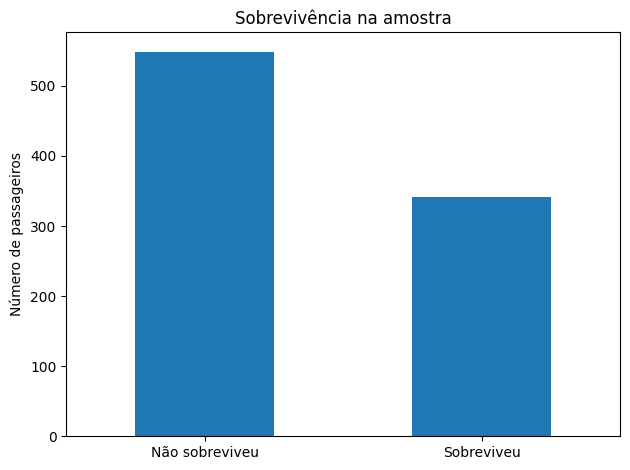

In [5]:
contagem = dados['sobreviveu'].value_counts().sort_index()
contagem.index = ['Não sobreviveu', 'Sobreviveu']
display(contagem.to_frame('pessoas'))
print(f"Taxa geral: {dados['sobreviveu'].mean():.1%}")
contagem.plot(kind='bar', rot=0, title='Sobrevivência na amostra')
plt.ylabel('Número de passageiros'); plt.tight_layout(); plt.show()

**Sua conclusão:** O que o gráfico mostra? A maioria sobreviveu?

## Pergunta 2 — Mulheres sobreviveram proporcionalmente mais que homens?
Compare **taxas**, e não apenas totais absolutos.

,pessoas,sobreviventes,taxa
sexo,,,
Feminino,314,233,74.2
Masculino,577,109,18.9


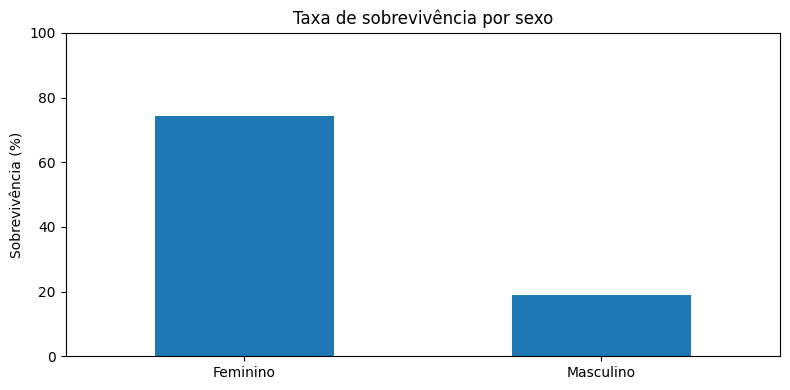

In [9]:
tabela_sexo = resumo_por('sexo')
display(tabela_sexo)
grafico_taxa(tabela_sexo, 'Taxa de sobrevivência por sexo')

**Sua conclusão:** Qual grupo teve maior taxa? Qual a diferença aproximada em pontos percentuais?

## Pergunta 3 — A classe da passagem estava associada à sobrevivência?

,pessoas,sobreviventes,taxa
classe,,,
1,216,136,63.0
2,184,87,47.3
3,491,119,24.2


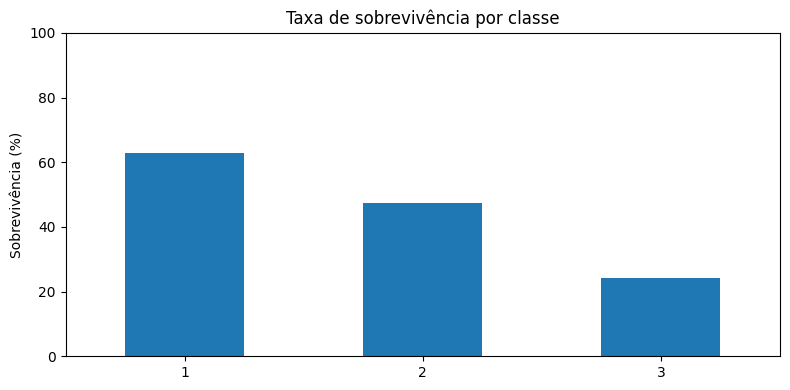

In [10]:
tabela_classe = resumo_por('classe')
display(tabela_classe)
grafico_taxa(tabela_classe, 'Taxa de sobrevivência por classe')

**Sua conclusão:** O padrão é semelhante nas três classes? O gráfico prova uma relação de causa e efeito?

## Pergunta 4 — Crianças tiveram maior taxa de sobrevivência que adultos?
**Regra da atividade:** criança = idade menor que 18 anos. Passageiros sem idade informada ficam fora desta comparação, mas não são removidos do restante da análise.

,pessoas,sobreviventes,taxa
faixa_etaria,,,
Adulto (18+),601,229,38.1
Criança (<18),113,61,54.0


Registros sem idade informada: 177


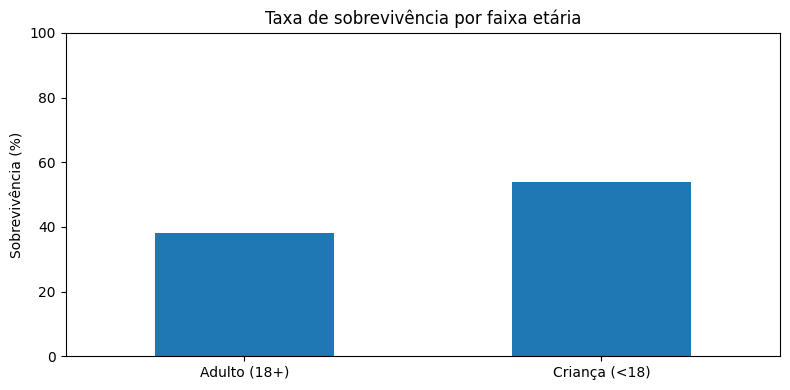

In [11]:
com_idade = dados.dropna(subset=['idade']).copy()
com_idade['faixa_etaria'] = com_idade['idade'].apply(lambda x: 'Criança (<18)' if x < 18 else 'Adulto (18+)')
tabela_idade = resumo_por('faixa_etaria', com_idade)
display(tabela_idade)
print('Registros sem idade informada:', dados['idade'].isna().sum())
grafico_taxa(tabela_idade, 'Taxa de sobrevivência por faixa etária')

**Sua conclusão:** O que acontece com os registros sem idade? Como isso limita nossa interpretação?

## Pergunta 5 — Viajar com familiares estava associado à sobrevivência?
Nesta base, familiares registrados são irmãos/cônjuge e pais/filhos a bordo; não representam necessariamente todos os acompanhantes.

,pessoas,sobreviventes,taxa
acompanhado,,,
Com familiares,354,179,50.6
Sem familiares,537,163,30.4


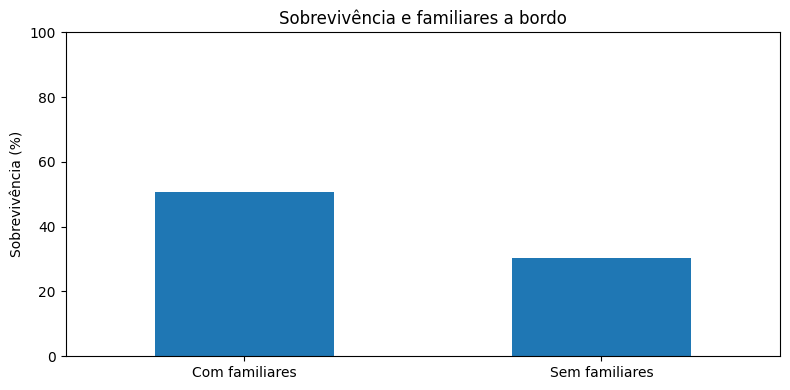

In [12]:
tabela_familia = resumo_por('acompanhado')
display(tabela_familia)
grafico_taxa(tabela_familia, 'Sobrevivência e familiares a bordo')

**Sua conclusão:** Há diferença? Isso significa que viajar acompanhado *causou* a sobrevivência?

## Pergunta 6 — O porto de embarque estava associado à sobrevivência?

,pessoas,sobreviventes,taxa
embarque,,,
Cherbourg,168,93,55.4
Queenstown,77,30,39.0
Southampton,644,217,33.7
NaN,2,2,100.0


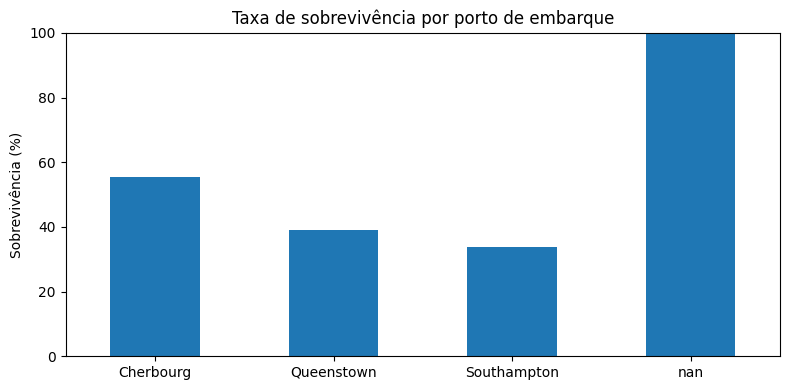

In [13]:
tabela_porto = resumo_por('embarque')
display(tabela_porto)
grafico_taxa(tabela_porto, 'Taxa de sobrevivência por porto de embarque')

**Sua conclusão:** Que diferenças aparecem? Como a classe da passagem poderia ajudar a explicar parte dessas diferenças?

## Pergunta 7 — O que descobrimos ao combinar sexo e classe?

pessoas  sobreviventes  taxa
sexo      classe                              
Feminino  1            94             91  96.8
          2            76             70  92.1
          3           144             72  50.0
Masculino 1           122             45  36.9
          2           108             17  15.7
          3           347             47  13.5

sexo,Feminino,Masculino
classe,,
1,96.8,36.9
2,92.1,15.7
3,50.0,13.5


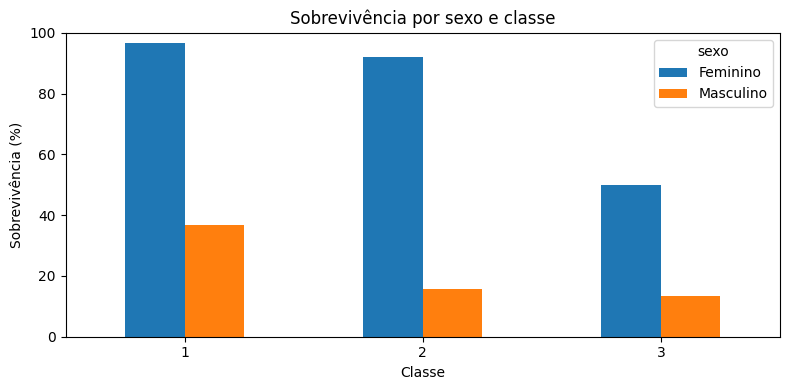

In [14]:
combinacao = dados.groupby(['sexo', 'classe'])['sobreviveu'].agg(
    pessoas='count', sobreviventes='sum', taxa='mean'
)
combinacao['taxa'] = (combinacao['taxa'] * 100).round(1)
display(combinacao)
matriz = dados.pivot_table(index='classe', columns='sexo', values='sobreviveu', aggfunc='mean') * 100
display(matriz.round(1))
matriz.plot(kind='bar', figsize=(8, 4), rot=0, ylim=(0, 100), title='Sobrevivência por sexo e classe')
plt.ylabel('Sobrevivência (%)'); plt.xlabel('Classe'); plt.tight_layout(); plt.show()

**Sua conclusão:** O que muda quando analisamos duas características ao mesmo tempo? Qual grupo teve maior e menor taxa?

## Encerramento — Preparação para a próxima aula

Responda em poucas linhas:

1. Quais características parecem associadas à sobrevivência nesta amostra?
R: sexo feminino, idade < 18 e questão financeira/classe.

2. Quais informações precisam de tratamento antes do treinamento?
R: idade, embarque, cabine.

3. Por que identificar padrões nos dados não garante que o modelo acertará novos passageiros?
R: porque não e uma escolha/dicertativa pois são dados reais.

4. Quais características você testaria primeiro em um modelo KNN? Justifique.
R:
**Na Etapa 2**, vamos preparar as variáveis, separar treino/validação e comparar hiperparâmetros do KNN. Ainda não faremos isso neste notebook.

### Preparação para a Etapa 2 — Seu cartão de embarque
Receba o cartão impresso **'Você sobreviveria ao Titanic?'** e preencha um perfil **fictício** com idade, sexo, classe, familiares, tarifa e porto de embarque. Não é necessário colocar dados pessoais verdadeiros. **Não tente descobrir a resposta ainda:** você utilizará esse perfil no Bloco 11 da Etapa 2.


1. Quais características parecem associadas à sobrevivência nesta amostra?

   R: sexo feminino, idade < 18 e questão financeira/classe.

2. Quais informações precisam de tratamento antes do treinamento?

   R: idade, embarque, cabine.

3. Por que identificar padrões nos dados não garante que o modelo acertará novos passageiros?

   R: porque não e uma escolha/dicertativa pois são dados reais.

4. Quais características você testaria primeiro em um modelo KNN? Justifique.
   R: